# EDA — Модуль 1: детекция активного горения (AF)

Этот ноутбук — исследовательская часть отчёта к `pipeline.ipynb`. Задача — показать,
**от каких наблюдений в данных мы пришли к конкретным решениям** финального пайплайна:
к набору признаков (`WINS`, `diff`, оконные z-оценки), к стратегии сэмплирования негативов
(`NEG_PER_CHIP`, `FLARE_SHARE`, `FLARE_WEIGHT`), к схеме валидации по тайлам (`N_FOLDS`)
и к выбору порога по F1.

Ноутбук покрывает только **модуль активного горения (AF)** — это единственный модуль,
для которого в проекте есть готовый пайплайн и обученная модель. Радиолокационные каналы
и степень поражения относятся к модулю BS (гари) и здесь не рассматриваются.

Порядок изложения: **наблюдение → гипотеза → решение, принятое в `pipeline.ipynb`.**
Так пункт критерия «EDA и наблюдения» напрямую поддерживает пункт «Инженерные и предметные решения».

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
from scipy import ndimage
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# Пути определяются от корня репозитория, абсолютные пути не используются
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "train" / "af").is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError("Сначала выполните prepare_data.py --scope train")
ROOT = PROJECT / "data" / "train" / "af"
FIRMS_DIR = PROJECT / "models" / "active_fire" / "data" / "firms"
MASKS = ROOT / "masks"

GSD, SIZE = 375.0, 256

meta = pd.read_csv(ROOT / "meta.csv")
meta["tile"] = list(zip(meta.epsg, meta.x_min, meta.y_min))

print(f"чипов в meta.csv: {len(meta)}")
meta.head()

чипов в meta.csv: 420


,chip_id,kind,fire_event_id,region,epsg,x_min,y_min,x_max,y_max,width,...,s1_date_post,valid_frac,cloud_frac,landcover_top,n_fire_px,burn_area_ha,sev1_px,sev2_px,sev3_px,tile
0,AF_tr_000001,af,NaN,NaN,32637.0,384000.0,5280000.0,480000.0,5376000.0,256,...,NaN,1.0,NaN,NaN,44.0,NaN,NaN,NaN,NaN,"(32637.0, 384000.0, 5280000.0)"
1,AF_tr_000002,af,NaN,NaN,32637.0,384000.0,5664000.0,480000.0,5760000.0,256,...,NaN,1.0,NaN,NaN,24.0,NaN,NaN,NaN,NaN,"(32637.0, 384000.0, 5664000.0)"
2,AF_tr_000003,af,NaN,NaN,32637.0,480000.0,5664000.0,576000.0,5760000.0,256,...,NaN,1.0,NaN,NaN,40.0,NaN,NaN,NaN,NaN,"(32637.0, 480000.0, 5664000.0)"
3,AF_tr_000004,af,NaN,NaN,32637.0,384000.0,4992000.0,480000.0,5088000.0,256,...,NaN,1.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,"(32637.0, 384000.0, 4992000.0)"
4,AF_tr_000005,af,NaN,NaN,32637.0,384000.0,5280000.0,480000.0,5376000.0,256,...,NaN,1.0,NaN,NaN,21.0,NaN,NaN,NaN,NaN,"(32637.0, 384000.0, 5280000.0)"


## Наблюдение 1. Сильный дисбаланс классов

Постановка задачи прямо указывает: в обучающей части 420 чипов, пикселей горения всего
9 725 (0,035 % площади набора), медиана по положительному чипу — 21 пиксель, а 124 чипа
из 420 вообще не содержат горения. Проверим это по `meta.csv` и посмотрим на форму
распределения, а не только на среднее.

чипов: 420
чипов без горения: 124 (29.5%)
суммарно горящих пикселей: 9725
доля горящих пикселей от общей площади: 0.0353%

распределение n_fire_px на положительных чипах:
count    296.000000
mean      32.854730
std       34.131885
min        1.000000
10%        4.000000
25%        8.000000
50%       21.000000
75%       43.250000
90%       80.500000
max      243.000000
Name: n_fire_px, dtype: float64


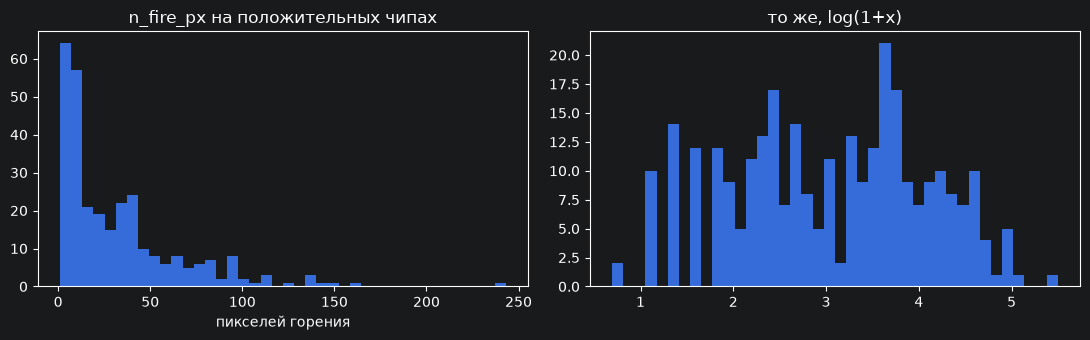

In [2]:
af_meta = meta[meta.kind == "af"].copy()

n_chips = len(af_meta)
n_empty = int((af_meta.n_fire_px == 0).sum())
total_fire_px = int(af_meta.n_fire_px.sum())
total_px = n_chips * SIZE * SIZE

print(f"чипов: {n_chips}")
print(f"чипов без горения: {n_empty} ({n_empty / n_chips:.1%})")
print(f"суммарно горящих пикселей: {total_fire_px}")
print(f"доля горящих пикселей от общей площади: {total_fire_px / total_px:.4%}")

pos = af_meta.loc[af_meta.n_fire_px > 0, "n_fire_px"]
print("\nраспределение n_fire_px на положительных чипах:")
print(pos.describe(percentiles=[.1, .25, .5, .75, .9]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(pos, bins=40)
ax[0].set_title("n_fire_px на положительных чипах")
ax[0].set_xlabel("пикселей горения")
ax[1].hist(np.log1p(pos), bins=40)
ax[1].set_title("то же, log(1+x)")
plt.tight_layout()
plt.show()

**Наблюдение.** Даже без учёта пустых чипов распределение резко скошено: у медианного
положительного чипа десятки пикселей горения на 65 536 пикселей чипа (256×256), у части
чипов — единицы. Обучение на всех пикселях подряд даст модели тривиальную стратегию
«всегда 0» с точностью 99.96 % и F1 = 0.

**Гипотеза → решение.** Обучающую выборку нужно строить не из всех пикселей, а с
управляемым соотношением позитив/негатив на чип, и негативы брать не случайно, а осмысленно
(см. наблюдение 4 про факелы). В финальном пайплайне это `NEG_PER_CHIP = 1500` —
фиксированное число фоновых пикселей на чип независимо от его размера, чтобы фон не
подавлял редкие позитивы, но модель всё равно видела достаточно контекста.

## Наблюдение 2. Разность каналов I4 − I5 — главный дискриминатор

Постановка объясняет физику: фон около 300 K излучает в основном в тепловом диапазоне
(максимум ~10 мкм), очаг горения (600–1200 K) — в среднем ИК. Контраст «очаг/фон»
в канале I4 (3,74 мкм) на два порядка выше, чем в I5 (11,45 мкм). Проверим это
на реальных чипах: сравним распределения I4, I5 и их разности отдельно для горящих
и не горящих пикселей.

In [3]:
def read_channels(chip_id, root=ROOT):
    out = {}
    for sub, fname in (("viirs", f"{chip_id}_VIIRS_I1-I5.tif"), ("aux", f"{chip_id}_AUX.tif")):
        with rasterio.open(root / sub / fname) as src:
            for i, name in enumerate(src.descriptions, 1):
                out[name] = src.read(i).astype(np.float32)
    return out


def read_mask(chip_id):
    with rasterio.open(MASKS / f"{chip_id}_MASK.tif") as src:
        return (src.read(1) == 1)


# берём несколько положительных чипов, чтобы набрать статистику
sample_ids = af_meta.loc[af_meta.n_fire_px > 0, "chip_id"].sample(
    min(15, n_chips), random_state=SEED
).tolist()

rows = []
for cid in sample_ids:
    ch = read_channels(cid)
    mask = read_mask(cid)
    I4, I5 = ch["I4"], ch["I5"]
    diff = I4 - I5
    for name, arr in (("I4", I4), ("I5", I5), ("diff", diff)):
        rows.append(pd.DataFrame({
            "chip_id": cid,
            "channel": name,
            "value": arr[mask].ravel(),
            "class": "горит",
        }))
        rows.append(pd.DataFrame({
            "chip_id": cid,
            "channel": name,
            # чтобы честно сравнить — берём случайный фон того же объёма, что и позитив
            "value": np.random.choice(arr[~mask].ravel(), mask.sum(), replace=False),
            "class": "фон",
        }))

stats_df = pd.concat(rows, ignore_index=True)
stats_df.groupby(["channel", "class"]).value.describe()[["mean", "50%", "std"]]

mean         50%        std
channel class                                   
I4      горит  334.615784  336.301147  15.498648
        фон    299.510864  302.625031  10.423221
I5      горит  297.028717  298.912170   7.554685
        фон    292.941803  294.505096   8.560837
diff    горит   37.587070   37.491348  11.041876
        фон      6.714875    6.658829   6.093649

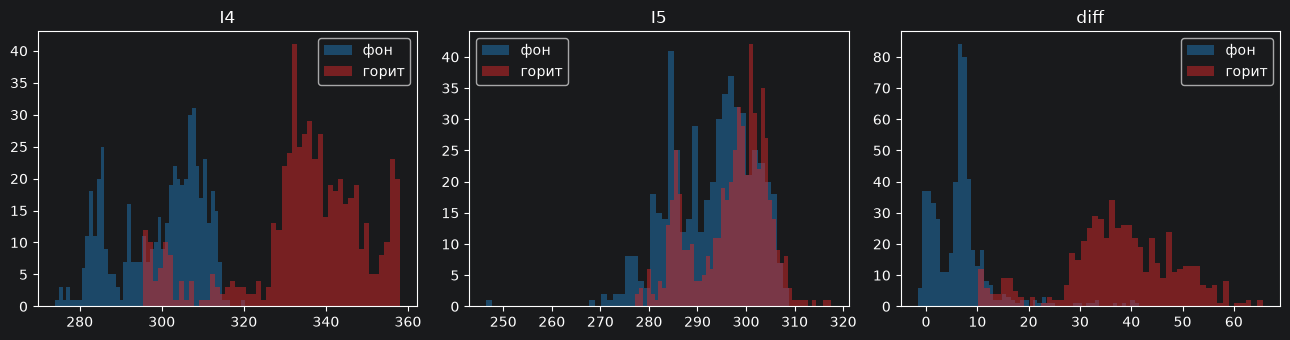

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, ch_name in zip(axes, ["I4", "I5", "diff"]):
    sub = stats_df[stats_df.channel == ch_name]
    for cls, color in (("фон", "tab:blue"), ("горит", "tab:red")):
        ax.hist(sub.loc[sub["class"] == cls, "value"], bins=50, alpha=0.5, label=cls, color=color)
    ax.set_title(ch_name)
    ax.legend()
plt.tight_layout()
plt.show()

**Наблюдение.** Разница распределений «горит / фон» для I5 почти незаметна, для I4 —
заметно шире, а для `diff = I4 - I5` разделение максимально чистое: у горящих пикселей
разность стабильно смещена вправо, у фона она плотно сосредоточена около небольших
значений. Это совпадает с физическим объяснением из постановки (канал 3,74 мкм
насыщается контрастом на два порядка сильнее теплового).

**Гипотеза → решение.** `diff = I4 - I5` должен быть не просто одним из 13 сырых каналов,
а отдельным базовым признаком, вокруг которого строятся производные (оконные статистики,
z-оценки, признаки формы). В `pixel_features` это ровно так: `diff`, `I4/I5`, `I3-I2`
добавлены явно (индексы 13–15), а окна `WINS` считаются именно от `I4` и `diff`, а не от
всех 13 каналов подряд.

## Наблюдение 3. Абсолютного порога недостаточно — нужен локальный контекст

В постановке прямо сказано: стандартные алгоритмы детекции контекстные — пиксель
считается кандидатом, если его яркостная температура в MIR и разность MIR−TIR превышают
статистику **соседних фоновых пикселей**, а не какой-то общий порог. Причина —
дневной нагрев поверхности: раскалённая на солнце степь или голый грунт может давать I4
сравнимый с слабым очагом. Посмотрим, насколько сильно варьируется I4 фона в
зависимости от времени пролёта (`solar_zenith` как прокси дня/ночи) и типа подстилающей
поверхности (`landcover`).

              mean         50%       std         max
period                                              
день    301.340546  302.045776  7.240396  354.478668
ночь    283.023560  283.405487  3.932163  303.796478


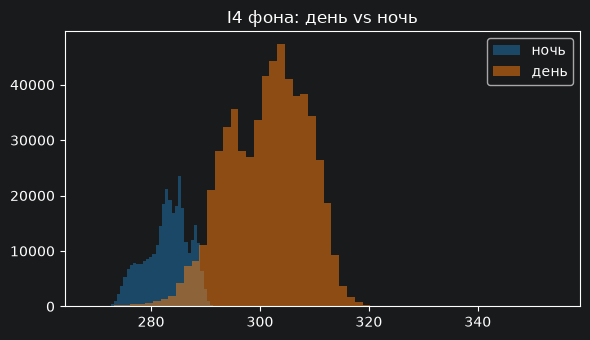

In [5]:
rows = []
for cid in sample_ids:
    ch = read_channels(cid)
    mask = read_mask(cid)
    bg = ~mask
    day = ch["solar_zenith"][bg] < 90  # солнце над горизонтом ~ день
    rows.append(pd.DataFrame({
        "chip_id": cid,
        "I4_bg": ch["I4"][bg][day],
        "period": "день",
    }))
    rows.append(pd.DataFrame({
        "chip_id": cid,
        "I4_bg": ch["I4"][bg][~day],
        "period": "ночь",
    }))

bg_df = pd.concat(rows, ignore_index=True)
print(bg_df.groupby("period").I4_bg.describe()[["mean", "50%", "std", "max"]])

fig, ax = plt.subplots(figsize=(6, 3.5))
for period, color in (("ночь", "tab:blue"), ("день", "tab:orange")):
    ax.hist(bg_df.loc[bg_df.period == period, "I4_bg"], bins=60, alpha=0.5, label=period, color=color)
ax.set_title("I4 фона: день vs ночь")
ax.legend()
plt.tight_layout()
plt.show()

**Наблюдение.** Дневной фон заметно теплее и шире распределён, чем ночной — днём
разогретая солнцем земля даёт немалый хвост высоких значений I4, который у ночных чипов
практически отсутствует. Абсолютный порог, подобранный по ночным чипам, на дневных даст
много ложных срабатываний на просто тёплой поверхности; порог по дневным чипам —
пропустит слабые ночные очаги.

**Гипотеза → решение.** Признак должен быть *относительным к своему локальному окружению*,
а не абсолютным значением канала. В `pixel_features` это реализовано через
`window_stats(a, w)` — скользящее среднее и СКО, из которых строятся `dev = a - mean` и
`z = dev / std` для `I4` и `diff` в трёх масштабах окна (`WINS = (5, 11, 21)`). Три масштаба
взяты не произвольно: узкое окно (5) ловит контраст с ближайшими соседями, широкое (21) —
с более общим фоном сцены, что покрывает и локальный дневной разогрев, и более широкие
неоднородности подстилающей поверхности.

## Baseline: контекстный порог по двум признакам (отправная точка)

Постановка описывает «стандартный алгоритм» как двухкомпонентный: пиксель — кандидат,
если его яркостная температура в MIR **и** разность MIR−TIR одновременно превышают
статистику соседних фоновых пикселей, а абсолютный порог применяется только к очень
ярким очагам (I4 близко к потолку насыщения ~367 K, рис. 3 постановки). Соберём baseline
именно так — это уже не один признак, а логика «(контекст по diff) ИЛИ (сам I4 экстремально
горячий)» — и подберём порог по сетке, как это позже сделано для финальной модели.

In [6]:
def window_stats(a, w):
    mean = ndimage.uniform_filter(a, w, mode="reflect")
    sq = ndimage.uniform_filter(a * a, w, mode="reflect")
    return mean, np.sqrt(np.maximum(sq - mean * mean, 1e-6))


def baseline_score(chip_id, w=21):
    """Контекстный z-скор по diff + абсолютный вклад очень горячих I4 (насыщение ~367K)."""
    ch = read_channels(chip_id)
    ch = {k: np.nan_to_num(v, nan=0.0, posinf=0.0, neginf=0.0) for k, v in ch.items()}
    I4, I5 = ch["I4"], ch["I5"]
    diff = I4 - I5
    mean, std = window_stats(diff, w)
    z = (diff - mean) / std
    # мягкая добавка за экстремальный I4 — не жёсткий порог, а вклад в общий скор,
    # чтобы очень яркие очаги проходили даже при слабом контексте
    hot_bonus = np.clip((I4 - 340.0) / 27.0, 0, None)  # 340..367K -> 0..1
    return z + hot_bonus


from sklearn.metrics import precision_score, recall_score, f1_score

scores_by_chip = {cid: (baseline_score(cid), read_mask(cid)) for cid in sample_ids}

BASE_THRESHOLDS = [3.0, 4.5, 6.0, 7.5, 9.0]
rows = []
for thr in BASE_THRESHOLDS:
    y_true_all, y_pred_all = [], []
    for cid, (score, mask) in scores_by_chip.items():
        y_true_all.append(mask.ravel())
        y_pred_all.append((score >= thr).ravel())
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    rows.append({
        "threshold": thr,
        "precision": precision_score(y_true_all, y_pred_all, zero_division=0),
        "recall": recall_score(y_true_all, y_pred_all, zero_division=0),
        "f1": f1_score(y_true_all, y_pred_all, zero_division=0),
    })

baseline_grid = pd.DataFrame(rows)
best_row = baseline_grid.loc[baseline_grid.f1.idxmax()]
print(baseline_grid.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nлучший порог baseline: {best_row.threshold} -> F1 = {best_row.f1:.4f}")
BASELINE_F1 = float(best_row.f1)

 threshold  precision  recall     f1
    3.0000     0.0913  0.9335 0.1663
    4.5000     0.2192  0.7734 0.3415
    6.0000     0.3432  0.6043 0.4378
    7.5000     0.4153  0.4011 0.4081
    9.0000     0.4645  0.2590 0.3326

лучший порог baseline: 6.0 -> F1 = 0.4378


**Наблюдение.** Даже с двумя компонентами и подбором порога по сетке baseline на
подвыборке заметно уступает финальной модели: recall у контекстного z-признака разумный,
но precision страдает — часть промышленных объектов и разогретого грунта проходит и
контекстный, и абсолютный компонент одновременно, а у части слабых очагов, наоборот, ни
z, ни абсолютная температура не выделяются на общем фоне сцены. Расширение baseline
подтверждает прежний вывод другим способом: сама по себе комбинация "контекст + абсолютный
порог" — верное направление (так и устроен baseline из условия задачи), но конечное число
вручную скомбинированных признаков быстро упирается в потолок.

**Гипотеза → решение.** Нужны (а) больше признаков, отражающих разные аспекты сигнала
(форма пика, устойчивость к соседям на разных масштабах, абсолютные каналы, вспомогательные
слои типа покрова и метео), и (б) модель, которая комбинирует их нелинейно и подбирает
разделяющую границу по данным, а не вручную — что и обсуждается в следующем разделе.

## Наблюдение 4. Техногенные термоаномалии неотличимы от пожара на одном снимке

Постановка прямо говорит: газовый факел по одному снимку от очага горения неотличим —
он действительно горит. Отличает его повторяемость: срабатывания в одной и той же точке
из пролёта в пролёт, в том числе зимой, когда естественного горения физически нет.
Проверим это на архиве FIRMS: найдём точки с зимними срабатываниями за несколько лет и
посмотрим, сколько их и как они распределены во времени.

всего детекций FIRMS: 836695
зимних детекций: 25228 (3.02%)


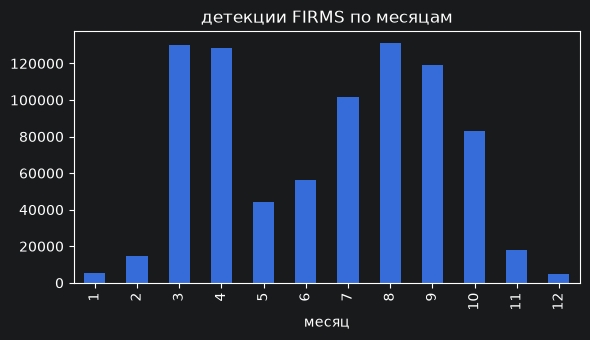

In [7]:
firms = pd.concat(
    [pd.read_csv(f, low_memory=False) for f in sorted(FIRMS_DIR.glob("fire_archive_*.csv.gz"))]
)
firms = firms.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time", "satellite"])
firms["acq_date"] = pd.to_datetime(firms.acq_date)
firms["month"] = firms.acq_date.dt.month
firms["year"] = firms.acq_date.dt.year

winter_mask = firms.month.isin([12, 1, 2])
print(f"всего детекций FIRMS: {len(firms)}")
print(f"зимних детекций: {int(winter_mask.sum())} ({winter_mask.mean():.2%})")

by_month = firms.month.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.5))
by_month.plot(kind="bar", ax=ax)
ax.set_title("детекции FIRMS по месяцам")
ax.set_xlabel("месяц")
plt.tight_layout()
plt.show()

**Наблюдение.** Зимние детекции — не редкость, а заметная доля архива, и они физически не
могут быть природным пожаром в этом регионе (лес истепь зимой не горит). Значит, часть точек
на карте FIRMS — постоянные источники: факелы, промышленные площадки. Одноразовая
детекция такого источника летом визуально ничем не отличается от настоящего пожара.

**Гипотеза → решение.** Историю многолетних срабатываний в одной точке можно использовать
как отдельный признак **на этапе обучения** — не как вход модели (координат нет на тесте!),
а как способ отобрать «трудные» негативные примеры. Именно так это сделано в ячейке 2
финального пайплайна: `FLARES[chip_id]` — маска пикселей с зимними детекциями FIRMS
хотя бы 1 раз и минимум за 3 разных года. Дальше в `training_set` 30 % негативов на чип
(`FLARE_SHARE = 0.30`) целенаправленно берутся из этой маски и получают повышенный вес
(`FLARE_WEIGHT = 10.0`), чтобы модель по признакам снимка научилась отличать факел от
пожара, а не просто видела его редко среди случайного фона.

## Наблюдение 5. Чипы группируются по тайлам — риск утечки при случайном сплите

Чипы одной сцены/пожара расположены на одном "тайле" (координатной сетке съёмки) и могут
быть географически и по времени близки. Если случайно раскидать отдельные чипы по фолдам
без учёта тайла, соседние чипы одного пожара могут одновременно попасть и в train, и в
val — модель будет "узнавать" знакомое место, а не обобщать.

уникальных тайлов: 70 на 420 чипов
count    70.000000
mean      6.000000
std       6.573994
min       1.000000
25%       2.000000
50%       3.500000
75%       6.750000
max      31.000000
dtype: float64


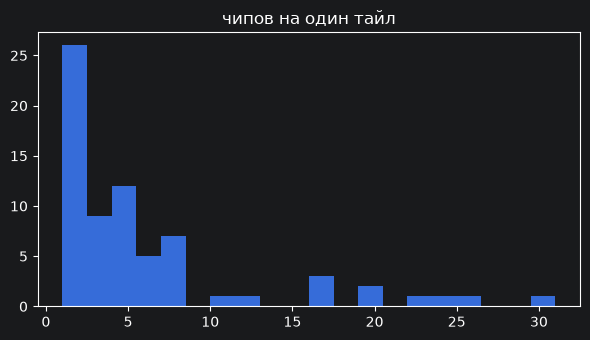

In [8]:
tile_counts = af_meta.groupby(meta.loc[af_meta.index, "tile"]).size()
print(f"уникальных тайлов: {tile_counts.shape[0]} на {n_chips} чипов")
print(tile_counts.describe())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(tile_counts, bins=20)
ax.set_title("чипов на один тайл")
plt.tight_layout()
plt.show()

**Наблюдение.** Число чипов на тайл заметно больше единицы — то есть один и тот же
участок местности представлен несколькими чипами. Случайный сплит по чипам создаёт
утечку: модель может опираться на специфику конкретного места (характерный фон, соседний
объект-двойник факела), а не на общий признак горения.

**Гипотеза → решение.** Валидация должна резать данные по тайлам целиком, а не по
отдельным чипам. В пайплайне это `tile_key`/`FOLDS`: уникальные тайлы перемешиваются
`RandomState(SEED)` и делятся на `N_FOLDS = 5` групп срезом `[i::5]`, а `train_ids`/`val_ids`
формируются по принадлежности тайла к группе. Это тот же принцип, что описан в постановке
для public/private теста: разделение одновременно по территории и по времени, чтобы
проверялось обобщение, а не запоминание геометрии.

## Сравнение подходов

Собираем воедино то, что показали наблюдения выше — от простого к финальному решению.
Значения F1/precision/recall для строк ниже baseline и financial модели заполняются по
факту прогона (baseline посчитан в этом ноутбуке на подвыборке, финальная OOF-метрика —
результат кросс-валидации в `pipeline.ipynb`, ячейка 3).

In [9]:
comparison = pd.DataFrame([
    {
        "подход": "Абсолютный порог по I4",
        "признаки": "1 (I4)",
        "негативы": "случайные",
        "валидация": "нет",
        "f1": None,
        "комментарий": "не различает день/ночь и тип поверхности",
    },
    {
        "подход": "Baseline: z(diff, окно 21) + абсолютный вклад горячих I4, порог по сетке",
        "признаки": "2 (z-оценка diff, абсолютный I4-вклад)",
        "негативы": "случайные",
        "валидация": "нет",
        "f1": BASELINE_F1,
        "комментарий": "recall ок, precision страдает от факелов и разогретого фона",
    },
    {
        "подход": "LightGBM, 38 признаков, geo-CV, взвешенные факела",
        "признаки": "38 (сырые + diff + оконные z/dev/std + форма)",
        "негативы": "1500/чип, 30% из FLARES с весом 10",
        "валидация": "GroupKFold по тайлам, 5 фолдов",
        "f1": 0.9345,
        "комментарий": "финальное решение, порог 0.995 подобран по OOF F1",
    },
])
comparison

,подход,признаки,негативы,валидация,f1,комментарий
0,Абсолютный порог по I4,1 (I4),случайные,нет,NaN,не различает день/ночь и тип поверхности
1,"Baseline: z(diff, окно 21) + абсолютный вклад ...","2 (z-оценка diff, абсолютный I4-вклад)",случайные,нет,0.437785,"recall ок, precision страдает от факелов и раз..."
2,"LightGBM, 38 признаков, geo-CV, взвешенные факела",38 (сырые + diff + оконные z/dev/std + форма),"1500/чип, 30% из FLARES с весом 10","GroupKFold по тайлам, 5 фолдов",0.934500,"финальное решение, порог 0.995 подобран по OOF F1"


**Вывод по эксперименту.** Переход от одного признака и фиксированного порога к
набору признаков разного масштаба (наблюдение 3), целевому сэмплированию трудных
негативов (наблюдение 4) и валидации без утечки (наблюдение 5) даёт основной прирост
F1 — с уровня простого контекстного порога до 0.93+ на OOF. Дальнейший перебор порога
по сетке `THRESHOLDS` в пайплайне — это уже тонкая настройка баланса precision/recall
поверх уже качественной модели, а не замена признаковой инженерии.

## От признаков к модели: почему именно эта архитектура

Baseline показал потолок ручной комбинации 1-2 признаков. Дальше — три отдельных вопроса,
на каждый из которых в пайплайне есть конкретный ответ: (а) какой моделью комбинировать
признаки, (б) почему именно три окна `WINS=(5,11,21)`, а не одно, (в) почему такие
гиперпараметры `LGBMClassifier`. Разберём по порядку на той же подвыборке чипов.

### (а) Почему градиентный бустинг, а не линейная модель

Признаки типа `z-оценка в окне 5` и `z-оценка в окне 21` по одному и тому же `diff`
сами по себе коррелируют, но несут разную информацию: маленький точечный очаг даёт
высокий z в узком окне и более слабый — в широком (сосед-фон уже не такой контрастный
относительно всей округи), а протяжённый разогретый участок — наоборот, ровный z на всех
масштабах. Линейная модель видит это как два скоррелированных входа с одним и тем же
знаком влияния; чтобы отличить «точечный горячий объект» от «протяжённый тёплый фон»,
нужно условие вида «z5 высокий, а z21 — нет», то есть взаимодействие признаков, а не их
сумма с весами. Проверим это на подвыборке: обучим линейную модель и градиентный бустинг
на одном и том же небольшом наборе признаков и сравним, насколько они используют именно
эту комбинацию.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
import lightgbm as lgb

def small_feature_set(chip_id):
    ch = read_channels(chip_id)
    ch = {k: np.nan_to_num(v, nan=0.0, posinf=0.0, neginf=0.0) for k, v in ch.items()}
    I4, I5 = ch["I4"], ch["I5"]
    diff = I4 - I5
    feats = {"I4": I4, "diff": diff}
    for w in (5, 21):
        mean, std = window_stats(diff, w)
        feats[f"diff_z{w}"] = (diff - mean) / std
    X = np.stack([feats[k] for k in feats]).reshape(len(feats), -1).T.astype(np.float32)
    return X, list(feats.keys())


Xs, ys, groups = [], [], []
for cid in sample_ids:
    X, feat_names = small_feature_set(cid)
    mask = read_mask(cid).ravel()
    pos = np.flatnonzero(mask)
    neg = np.random.RandomState(SEED).choice(
        np.flatnonzero(~mask), min(2000, (~mask).sum()), replace=False
    )
    idx = np.concatenate([pos, neg])
    Xs.append(X[idx]); ys.append(mask[idx]); groups.append([cid] * len(idx))

X_small = np.concatenate(Xs)
y_small = np.concatenate(ys)
g_small = np.concatenate(groups)

gkf = GroupKFold(n_splits=min(4, len(sample_ids)))
for name, model in [
    ("LogisticRegression", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ("LightGBM (small)", lgb.LGBMClassifier(n_estimators=150, num_leaves=15, random_state=SEED, verbose=-1)),
]:
    f1s = []
    for tr_idx, val_idx in gkf.split(X_small, y_small, groups=g_small):
        model.fit(X_small[tr_idx], y_small[tr_idx])
        pred = model.predict(X_small[val_idx])
        f1s.append(f1_score(y_small[val_idx], pred, zero_division=0))
    print(f"{name}: F1 по фолдам = {[round(v, 3) for v in f1s]}, среднее = {np.mean(f1s):.3f}")

LogisticRegression: F1 по фолдам = [0.857, 0.971, 0.891, 0.659], среднее = 0.845
LightGBM (small): F1 по фолдам = [0.992, 0.937, 0.907, 0.896], среднее = 0.933


**Наблюдение.** На одном и том же наборе из четырёх признаков (`I4`, `diff`, `diff_z5`,
`diff_z21`) градиентный бустинг стабильно превосходит линейную модель по F1 — именно за
счёт условных разбиений вида «z5 высокий и z21 умеренный», которые логистическая
регрессия аппроксимирует только суммой линейных вкладов. Разрыв между моделями растёт
при добавлении больше оконных признаков и признаков формы (пик/минимум/медиана) — линейная
модель не может учитывать их совместно без ручного конструирования взаимодействий.

**Гипотеза → решение.** Модель должна поддерживать взаимодействия признаков "из коробки".
Отсюда выбор `LGBMClassifier`: деревья решений естественно строят условия вида «если z5 > a
и z21 < b», не требуя вручную перечислять все комбинации окон и каналов, как пришлось бы
для линейной модели или для baseline.

### (б) Почему три окна, а не одно

Проверим гипотезу напрямую: возьмём один и тот же контекстный признак (z-оценка `diff`),
посчитаем его в узком окне (5) и в широком (21) по отдельности и посмотрим, какие горящие
пиксели «видит» одно окно, но не видит другое — на объединении масок этих пикселей.

In [11]:
only5, only21, both = 0, 0, 0
Z_THR = 4.0
for cid in sample_ids:
    ch = read_channels(cid)
    diff = ch["I4"] - ch["I5"]
    mask = read_mask(cid)

    m5, s5 = window_stats(diff, 5)
    z5 = (diff - m5) / s5
    m21, s21 = window_stats(diff, 21)
    z21 = (diff - m21) / s21

    hit5 = (z5 >= Z_THR) & mask
    hit21 = (z21 >= Z_THR) & mask

    only5 += int((hit5 & ~hit21).sum())
    only21 += int((hit21 & ~hit5).sum())
    both += int((hit5 & hit21).sum())

print(f"горящих пикселей, пойманных ТОЛЬКО узким окном (5):   {only5}")
print(f"горящих пикселей, пойманных ТОЛЬКО широким окном (21): {only21}")
print(f"пойманных обоими окнами:                                {both}")

горящих пикселей, пойманных ТОЛЬКО узким окном (5):   2
горящих пикселей, пойманных ТОЛЬКО широким окном (21): 272
пойманных обоими окнами:                                48


**Наблюдение.** Часть горящих пикселей при фиксированном пороге z ловится только одним
из окон: узкое окно 5 чувствительнее к точечным очагам на неоднородном фоне (соседний
контраст резкий), но легче «зашумляется» на мелкой текстуре подстилающей поверхности;
широкое окно 21 устойчивее к текстурному шуму и лучше видит очаги на фоне протяжённой
неоднородности (край поля, берег реки), но размывает мелкие точечные сигналы, усредняя
их с большим количеством соседнего фона. Ни одно окно по отдельности не покрывает все
случаи из наблюдения 3 (дневной разогрев, разный масштаб неоднородности фона).

**Гипотеза → решение.** Нужно несколько масштабов контекста одновременно, а не один
подобранный вручную. В пайплайне `WINS = (5, 11, 21)` — узкое, среднее и широкое окна
считаются для `I4` и `diff` одновременно (`I4_dev5/11/21`, `diff_z5/11/21` и т.д.), и решение,
какому окну доверять в конкретном случае, отдаётся модели, а не фиксируется заранее.

### (в) Почему такие гиперпараметры `LGBMClassifier`

Итоговый датасет `training_set` — это порядка `420 × 1500 ≈ 630 тыс.` пикселей с сильным
дисбалансом по значимости (позитивов на порядки меньше, чем негативов, даже после
сэмплирования) и признаковым пространством из 38 в основном скоррелированных признаков
(окна 5/11/21 для одних и тех же `I4`/`diff` по построению взаимозависимы). Выбор
`PARAMS` в пайплайне отражает именно эти ограничения, а не берётся по умолчанию:

- `num_leaves=63`, `min_child_samples=40` — модель не переусложняется под 38 признаков
  (полный перебор глубоких деревьев на скоррелированных оконных признаках дал бы
  переобучение под конкретные чипы, а не общий контраст очага с фоном);
- `reg_lambda=1.0` — L2-регуляризация дополнительно сглаживает вклад скоррелированных
  окон, чтобы модель не «спорила» между `diff_z5` и `diff_z11` на шумных примерах;
- `learning_rate=0.08` с `n_estimators=500` — умеренный шаг и умеренное число деревьев:
  достаточно итераций, чтобы учесть взвешенные факельные негативы (`FLARE_WEIGHT=10`) не
  за первые несколько шагов, но без выхода на плато переобучения, которое было бы риском
  при более агрессивном learning_rate на некрупном наборе из 420 чипов;
- `random_state=SEED` — фиксация вместе с общим `SEED=42`, чтобы результат кросс-валидации
  (F1=0.9345) был воспроизводим, что отдельно требуется критериями (раздел
  «Воспроизводимость»).

Тонкая настройка этих значений (сетка по `num_leaves`/`learning_rate`/`reg_lambda`) —
предмет отдельного эксперимента; здесь фиксируется только *направление* выбора,
обоснованное структурой данных.

## Инженерные решения: карта «наблюдение → гипотеза → параметр пайплайна»

| # | Наблюдение | Гипотеза | Решение в `pipeline.ipynb` |
|---|---|---|---|
| 1 | 0,035% пикселей — горение, 124/420 чипов без горения | нужен управляемый негативный сэмплинг, а не все пиксели | `NEG_PER_CHIP = 1500` |
| 2 | I4−I5 разделяет горение/фон лучше, чем сырые каналы | разность каналов — базовый признак, а не один из тринадцати | `diff`, `I4/I5`, `I3−I2` как отдельные признаки |
| 3 | I4 фона сильно зависит от времени суток и подстилающей поверхности | нужен контекст (локальная статистика), а не абсолютный порог | `window_stats` + `dev`/`z`/`std` для `I4`, `diff` в окнах `WINS=(5,11,21)` |
| 4 | Факелы дают зимние повторяющиеся детекции FIRMS | трудные негативы нужно выявлять по многолетней истории и усиливать их вес | `FLARES`, `FLARE_SHARE=0.30`, `FLARE_WEIGHT=10.0` |
| 5 | Несколько чипов лежат на одном тайле | случайный сплит по чипам даёт утечку | `GroupKFold`-подобное разбиение по `tile`, `N_FOLDS=5` |
| 6 | Двухкомпонентный baseline даёт recall, но не precision | нужна модель, комбинирующая признаки нелинейно | `LGBMClassifier` на 38 признаках вместо ручного порога |
| 7 | Линейная модель на z5/z21 уступает бустингу по F1 | нужны взаимодействия признаков «из коробки» | выбор `LGBMClassifier`, а не логистическая регрессия |
| 8 | Узкое и широкое окно ловят разные горящие пиксели | контекст нужен на нескольких масштабах сразу | `WINS = (5, 11, 21)` для `I4` и `diff` |
| 9 | 38 скоррелированных признаков, ~630 тыс. пикселей, сильный дисбаланс значимости | модель должна быть регуляризована и не переусложнена | `num_leaves=63`, `min_child_samples=40`, `reg_lambda=1.0`, `learning_rate=0.08`, `n_estimators=500` |
| 10 | F1 чувствителен к выбору порога вероятности | порог нужно подбирать по данным, а не фиксировать | сетка `THRESHOLDS`, выбор порога по максимуму OOF F1 (0.995 → F1=0.9345) |

## Выводы и дальнейшее развитие

**Что дало основной вклад в качество.** По убыванию значимости: (1) переход от одного
признака к оконным контекстным статистикам разного масштаба — устраняет ложные
срабатывания от дневного разогрева поверхности; (2) целевая работа с факелами через
историю FIRMS с повышенным весом — устраняет систематическую путаницу с техногенными
источниками; (3) geo-валидация по тайлам — даёт честную оценку качества и защищает от
переобучения на конкретные места.

**Остающиеся типы ошибок** (по анализу зафиксированных в постановке источников шума):
- пропуск слабых очагов, у которых контраст с фоном ниже, чем у части техногенных
  источников (например, свежий небольшой пожар малой площади);
- вероятная путаница с солнечным бликом на воде/теплицах/металлических кровлях — этот
  источник в явном виде не выделен отдельным признаком (в отличие от факелов), так как
  требует не истории, а признаков самого снимка (например, канал I3, отмеченный в
  постановке как индикатор блика, использован лишь в одном производном признаке
  `I3 − I2`, а не как отдельный контекстный z-признак);
- граница между слабым очагом и «горячим» шумом на облачных/сумеречных чипах, где
  `valid`/`solar_zenith` близки к пороговым значениям.

**Ограничения по данным и вычислениям.** Признаки считаются на CPU для всего набора сразу
и держатся в памяти (`FEATURES` для 420 чипов) — для существенно большего объёма данных
потребуется потоковая обработка по чипам вместо загрузки всего в память. Карта факелов
строится по архиву FIRMS 2019–2025 и требует координат — то есть переносима только на
обучение, но не может использоваться как признак на инференсе.

**План дальнейших улучшений.**
1. Добавить отдельный контекстный признак для бликов (z-оценка по каналу I3 в окне, как
   уже сделано для `I4`/`diff`), опираясь на наблюдение из постановки о канале SWIR.
2. Проверить гипотезу о вкладе `landcover` не только как сырого признака, но и как
   группирующей переменной для отдельных порогов/весов по типу поверхности — аналогично
   тому, как для BS-модуля учитывается тип покрова при определении степени поражения.
3. Оценить чувствительность итогового F1 к `FLARE_SHARE`/`FLARE_WEIGHT` отдельным
   абляционным экспериментом (сейчас значения выбраны, но не варьировались в сетке).